# nbook to create a dataframe of cell properties for mothly datasets
- what it does:
    - calculate some missing cell feature properties
    - converting cell feature properties to lifetime-integrated cell properties
    - separate anvil feature properties
    - domain wide calculation
- input: linking/filtered for the months
- output: final_dataframes for June and December for ICON and OBS

# load packages 

In [2]:
import warnings

# ignore general categories
for cat in [FutureWarning, RuntimeWarning, UserWarning]:
    warnings.filterwarnings("ignore", category=cat)

# ignore specific repeated messages
for msg in [
    "pyproj unable to set PROJ database path",
    "As of v1.6.0, segmentation with time length 1",
    "Using DEFAULT_SPHERICAL_EARTH_RADIUS"
]:
    warnings.filterwarnings("ignore", message=msg)


import numpy as np
import xarray as xr
import os
import pandas as pd

from pathlib import Path
import sys
import tobac

# load data

In [3]:
inputdir = "../output/linking/filtered"
models = ["ICON","OBS"]
timeperiods = ["JUNE","DECEMBER"]

In [4]:
## load tracks
ds = {}
for model in models: 
    ds[model] = {}
    for timeperiod in timeperiods: 
        file = os.path.join(inputdir,f"all_tracks_filtered_{model}_{timeperiod}.h5")
        Tracks = pd.read_hdf(file, key='table') 
        Tracks = Tracks.rename(columns={
            "min_tb": "min_tb_anvil",
            "mean_iwp": "mean_iwp_anvil",
            "max_iwp": "max_iwp_anvil",
            "total_iwp":"total_iwp_anvil",
            #"rain_volume": "rain_volume_cell"
        })
        #ds[model][timeperiod] = Tracks.reset_index()
        # solve issue with numeric columns 
        numeric_cols = [c for c in Tracks.columns if 'dtiwp' in c or 'mean_iwp_cell' in c]
        Tracks[numeric_cols] = Tracks[numeric_cols].apply(pd.to_numeric, errors='coerce')
        ds[model][timeperiod] = Tracks.reset_index()

## arguements

In [4]:
savedir = Path("../output/final_dataframes")
savedir.mkdir(parents=True, exist_ok=True)

domain_area_m2 = 255032272355328.0

# def functions

In [5]:
def add_min_distance(df, exclude_mask_function, group_col="frame",
                      lat_col="latitude", lon_col="longitude"):
    """
    General minimum-distance-to-other-feature operator.
    """
    tmp = []

    for _, df_one_frame in df.groupby(group_col, sort=False):
        lat_arr = df_one_frame[lat_col].values
        lon_arr = df_one_frame[lon_col].values
        n = len(df_one_frame)
        result = np.full(n, np.nan)

        for i in range(n):
            mask = exclude_mask_function(df_one_frame, i)
            if not mask.any():
                continue  # C(i) empty -> leave as NaN (e.g. lone feature in frame)
            distances = tobac.analysis.spatial.haversine(lat_arr[i], lon_arr[i], lat_arr[mask], lon_arr[mask])
            result[i] = distances.min()

        tmp.append(pd.Series(result, index=df_one_frame.index))

    return pd.concat(tmp).reindex(df.index)

    
def exclude_none(df, i):
    not_self = np.arange(len(df)) != i
    return not_self
def exclude_sisters(df,i):
    not_self = np.arange(len(df)) != i
    not_sister = df["feature_anvil"].values != df["feature_anvil"].values[i]
    return not_self & not_sister


# Cell feature properties

In [6]:
for model in models: 
    for timeperiod in timeperiods: 
        Tracks = ds[model][timeperiod]

        # new rain amount (again in pendegrass normlaization
        Tracks = Tracks.drop(columns=["rain_volume"], errors="ignore")
        Tracks["rain_volume_cell"]= Tracks["mean_precip_cell"] * Tracks["area_cell"] 
        
        # sister cells = cells under the same anvil
        # n sister cells => number of sister cells at a given time excluding the cell itself
        Tracks["n_sister_cells"] = (Tracks.groupby(["frame", "feature_anvil"])["track"].transform("nunique") - 1)
        
        # fraction of rain from cell falling in anvil
        #Tracks["frac_rain_cell_rain_anvil"] = Tracks["total_precip_cell"] / Tracks["total_precip_anvil"]
        
        # min distacne to non sister
        Tracks["min_dist_nonsister_cell_km"] = add_min_distance(Tracks,exclude_sisters)
        
        # nearest neightbour 
        Tracks["min_dist_cell_km"] = add_min_distance(Tracks,exclude_none)
        #tobac.analysis.spatial.calculate_nearestneighbordistance(Tracks, method_distance="latlon")

        ##################################
        ##################################
        # anvil related
        Tracks["rain_volume_anvil"]= Tracks["mean_precip_anvil"] * Tracks["area_anvil"]  # as pendergrass total rain normalized to mm/h

        # n children
        Tracks["n_children_anvil"] = Tracks.groupby(["frame", "feature_anvil"])["track"].transform("nunique") 

        #  iwp amount (aka total iwp) 
        Tracks["iwp_volume_anvil"]= Tracks["mean_iwp_anvil"] * Tracks["area_anvil"]  # kg

        #Tracks["min_dist_anvil_km"] =  add_min_distance(Tracks,exclude_none,group_col = "time",lat_col ="latitude_anvil",lon_col= "longitude_anvil")
        ########################################
        ######################################
        
        # assign to ds
        ds[model][timeperiod] = Tracks

       
        


In [7]:
Tracks.columns

Index(['index', 'frame', 'idx_cell', 'hdim_1', 'hdim_2', 'num_cell',
       'threshold_value_cell', 'feature', 'time', 'timestr', 'latitude',
       'longitude', 'ncells_cell', 'mean_precip_cell', 'total_precip_cell',
       'max_precip_cell', 'area_cell', 'd_eq_cell', 'total_dtiwp_cell',
       'mean_iwp_cell', 'total_iwp_cell', 'idx_anvil', 'hdim_1_anvil',
       'hdim_2_anvil', 'num_anvil', 'threshold_value_anvil', 'feature_anvil',
       'latitude_anvil', 'longitude_anvil', 'ncells_anvil', 'mean_iwp_anvil',
       'total_iwp_anvil', 'max_iwp_anvil', 'min_tb_anvil', 'area_anvil',
       'd_eq_anvil', 'mean_precip_anvil', 'total_precip_anvil',
       'max_precip_anvil', 'total_dtiwp_anvil', 'cell', 'time_cell', 'track',
       'time_track', 'v', 'rain_amount', 'rain_volume_cell', 'n_sister_cells',
       'min_dist_nonsister_cell_km', 'min_dist_cell_km', 'rain_volume_anvil',
       'n_children_anvil', 'iwp_volume_anvil'],
      dtype='object')

# Lifetime-integrated cell properties

In [8]:
cellprops ={}
PE_diag = {}
for model in models: 
    cellprops[model] = {}
    PE_diag[model] = {}
    
    for timeperiod in timeperiods: 
        Tracks = ds[model][timeperiod]
        
        cellprops[model][timeperiod] = Tracks.groupby("track").agg(
        
            # precip intensity
            mean_precip_cell_mean=("mean_precip_cell", "mean"),   # lifetime-averaged mean precip rate
            max_precip_cell_max=("max_precip_cell", "max"),       # max of max precip rate over lifetime
            total_precip_cell_mean =("total_precip_cell", "mean"), # avergae total rain rate
            rain_volume_cell_sum =("rain_volume_cell", "sum"), 
            rain_volume_cell_mean =("rain_volume_cell", "mean"),  # rain amount normalzed to hour (bc all delkta t are 3 hours=> directly mean, no 3* / 3
            
        
            # diagostics? 
            lifetime_cell= ("time_track", "max"),
            area_cell_mean          = ("area_cell", "mean"),
            d_eq_cell_mean          = ("d_eq_cell", "mean"),
            d_eq_cell_max  = ("d_eq_cell", "max"),
            velo_cell_mean = ("v","mean"),
        
        
            # aggregation 
            n_sister_cells_max  = ("n_sister_cells", "max"),
            n_sister_cells_mean  = ("n_sister_cells", "mean"),
        
             
            #min_dist_nonsister_cell_km_min = ("min_dist_nonsister_cell_km","min"),
            min_dist_nonsister_cell_km_mean = ("min_dist_nonsister_cell_km","mean"),


            #min_dist_cell_km_min = ("min_dist_cell_km","min"),
            min_dist_cell_km_mean = ("min_dist_cell_km","mean"),


            mean_iwp_cell_mean = ('mean_iwp_cell', "mean"),
            # max_iwp_cell_max = ("max_iwp_cell","max"),
            
            # total_iwp_cell_mean = ('total_iwp_cell', "mean"),
            # iwp_volume_cell_sum =("iwp_volume_cell","sum"),


        
            # related to anvil duplicates
            mean_precip_anvil_mean = ('mean_precip_anvil', "mean"),
            total_precip_anvil_mean = ('mean_precip_anvil', "mean"),
            
            rain_volume_anvil_sum =("rain_volume_anvil","sum"),
            rain_volume_anvil_mean =("rain_volume_anvil","mean"),
            
          
            mean_iwp_anvil_mean = ('mean_iwp_anvil', "mean"),
            max_iwp_anvil_max = ("max_iwp_anvil","max"),
            
            total_iwp_anvil_mean = ('total_iwp_anvil', "mean"),
            iwp_volume_anvil_sum =("iwp_volume_anvil","sum"),

            
                
            area_anvil_mean          = ("area_anvil", "mean"),
            d_eq_anvil_mean          = ("d_eq_anvil", "mean"),
            d_eq_anvil_max          = ("d_eq_anvil", "max"),
            
            min_tb_anvil_min =  ("min_tb_anvil", "min"),

            #min_dist_anvil_km_mean = ("min_dist_anvil_km","mean"),
                   

            n_children_anvil_mean = ("n_children_anvil","mean"),

            time = ("time","min") ,# starttime



            ).reset_index()

        
        cellprops[model][timeperiod]["lifetime_cell"] = (cellprops[model][timeperiod]["lifetime_cell"].dt.total_seconds() / 3600)

        # # storm-integrated PE   
        PE_diag[model][timeperiod] = Tracks.groupby("track").agg(
            # storm integrated precip rate and iwp tendenc y
            P_anvil = ('total_precip_anvil', "sum"),
            P_cell = ('total_precip_cell', "sum"),
            dtiwp_cell = ('total_dtiwp_cell', "sum"),
            dtiwp_anvil = ('total_dtiwp_anvil', "sum"),
        ).reset_index() 

        PE_diag[model][timeperiod]["PE_anvil"] = ( 100 * PE_diag[model][timeperiod]["P_anvil"]/ (PE_diag[model][timeperiod]["P_anvil"] + PE_diag[model][timeperiod]["dtiwp_anvil"]))
        PE_diag[model][timeperiod]["PE_cell"] = ( 100 * PE_diag[model][timeperiod]["P_cell"]/ (PE_diag[model][timeperiod]["P_cell"] + PE_diag[model][timeperiod]["dtiwp_cell"]))

      
        cellprops[model][timeperiod]["PE_anvil"]  = PE_diag[model][timeperiod]["PE_anvil"] 
        cellprops[model][timeperiod]["PE_cell"]  = PE_diag[model][timeperiod]["PE_cell"] 



<Axes: >

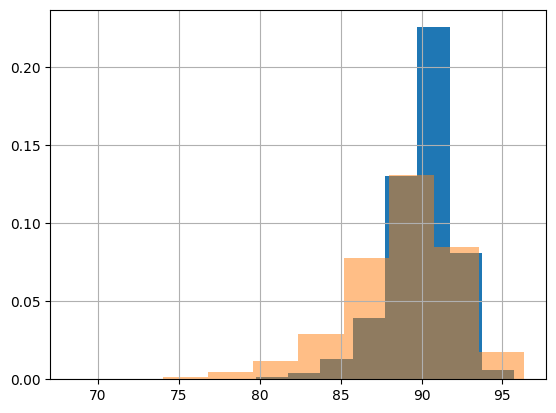

In [9]:
#cellprops["ICON"]["DECEMBER"]["PE_anvil"].hist()
cellprops["ICON"]["JUNE"]["PE_anvil"].hist(density = True)
cellprops["OBS"]["JUNE"]["PE_anvil"].hist(density = True, alpha = 0.5)

# Reduce feature proeprties to the ones that should be saved

### cell features

In [10]:
columns_tracks = cellprops["ICON"]["JUNE"].columns    # aggregated (track-level)
columns_features = ds["ICON"]["JUNE"].columns          # raw (feature-level)

### anvil feature dataset

In [11]:
# raw anvil columns from ds
anvil_cols_raw = [c for c in columns_features if "anvil" in c.lower()]
anvil_cols_used= ["time","feature_anvil"]+[c for c in anvil_cols_raw if any(col.startswith(c) for col in columns_tracks)] 

anvilfeatures ={}
for model in models: 
    anvilfeatures[model] = {}
    for timeperiod in timeperiods: 
        Tracks = ds[model][timeperiod]
        tmp = (Tracks.drop_duplicates(subset=['time', 'feature_anvil'], keep='first').reset_index(drop=True))

        # add min distance before column filtering
        tmp = tmp.rename(columns={
            "latitude_anvil": "latitude",
            "longitude_anvil": "longitude",
        })
        tmp["min_dist_anvil_km"] = add_min_distance(tmp,exclude_none,group_col = "time")

        # filter for columsn 
        tmp = tmp[anvil_cols_used+["min_dist_anvil_km"]]

        # convective rain amount
        convectiverain = Tracks.groupby(['time', 'feature_anvil'])['rain_volume_cell'].sum().reset_index().rename(columns={'rain_volume_cell': 'convective_rain_volume_anvil'})

        # merge on the composite key -> guarantees correct row alignment
        tmp = tmp.merge(convectiverain, on=["time", "feature_anvil"], how="left")

        #tmp["non_convection_rain_volume_anvil"] = tmp["rain_volume_anvil"]-tmp["convective_rain_volume_anvil"] => gives minus values 
        tmp["fraction_convection_rain_volume_anvil"] = tmp["convective_rain_volume_anvil"]/tmp["rain_volume_anvil"]
        tmp["fraction_convection_rain_volume_anvil"] = tmp["fraction_convection_rain_volume_anvil"].where(tmp["fraction_convection_rain_volume_anvil"] <= 1)
 
        
        anvilfeatures[model][timeperiod] = tmp


In [12]:
anvilfeatures["ICON"]["JUNE"].columns

Index(['time', 'feature_anvil', 'mean_iwp_anvil', 'total_iwp_anvil',
       'max_iwp_anvil', 'min_tb_anvil', 'area_anvil', 'd_eq_anvil',
       'mean_precip_anvil', 'total_precip_anvil', 'rain_volume_anvil',
       'n_children_anvil', 'iwp_volume_anvil', 'min_dist_anvil_km',
       'convective_rain_volume_anvil',
       'fraction_convection_rain_volume_anvil'],
      dtype='object')

### cell features 
select relevant cell feature columns from ds

In [14]:

cell_cols_raw = [c for c in columns_features if "cell" in c.lower()]
cell_cols_used= ["time","feature"] +[c for c in cell_cols_raw if any(col.startswith(c) for col in columns_tracks)] 


       
cellfeatures ={}
for model in models: 
    cellfeatures[model] = {}
    for timeperiod in timeperiods: 
        cellfeatures[model][timeperiod] = ds[model][timeperiod][cell_cols_used]
        
    

# Calculate domain wide variables

In [15]:
ds = cellfeatures["ICON"]["JUNE"].groupby("time").size()

In [16]:
domain = {}
# anvil counts
for model in models: 
    domain[model] = {}
    for timeperiod in timeperiods: 
        
        cf = cellfeatures[model][timeperiod]
        af = anvilfeatures[model][timeperiod]
        # cell counts
        n_cells = cf.groupby("time").size().reset_index(name="n_cells")
        # anvil counts
        n_anvils = af.groupby("time").size().reset_index(name="n_anvils")
        # cell area sum 
        cell_area_sum = cf.groupby("time")["area_cell"].sum().reset_index(name="cell_area_sum")
        # anvil area sum 
        anvil_area_sum = af.groupby("time")["area_anvil"].sum().reset_index(name="anvil_area_sum")
        # rain amount cell sum
        rain_cell_sum = cf.groupby("time")["rain_volume_cell"].sum().reset_index(name="rain_volume_cell_sum")
          
        # rain amount anvil sum
        rain_anvil_sum = af.groupby("time")["rain_volume_anvil"].sum().reset_index(name="rain_volume_anvil_sum")

        # put together
        summary = n_cells
        for other in [n_anvils, cell_area_sum, anvil_area_sum, rain_cell_sum, rain_anvil_sum]:
            summary = summary.merge(other, on="time", how="outer")

        domain[model][timeperiod] = summary    

In [17]:
domain["ICON"]["JUNE"]

,time,n_cells,n_anvils,cell_area_sum,anvil_area_sum,rain_volume_cell_sum,rain_volume_anvil_sum
0,2023-06-01 00:00:00,62,42,8.375386e+10,2.648579e+12,1.581318e+12,6.146144e+12
1,2023-06-01 03:00:00,76,49,1.024948e+11,2.854858e+12,1.995693e+12,6.227536e+12
2,2023-06-01 06:00:00,94,58,1.270345e+11,3.089771e+12,2.347340e+12,6.191572e+12
3,2023-06-01 09:00:00,120,75,1.453337e+11,3.711778e+12,2.762843e+12,7.854101e+12
4,2023-06-01 12:00:00,132,82,1.502158e+11,3.428698e+12,2.835717e+12,7.553972e+12
...,...,...,...,...,...,...,...
232,2023-06-30 09:00:00,112,66,1.412140e+11,4.387946e+12,2.950685e+12,8.433928e+12
233,2023-06-30 12:00:00,95,51,1.235690e+11,3.637351e+12,2.440477e+12,6.953581e+12
234,2023-06-30 15:00:00,82,54,1.062907e+11,3.214513e+12,1.982736e+12,6.169197e+12
235,2023-06-30 18:00:00,72,47,8.880223e+10,2.749923e+12,1.664275e+12,6.007077e+12


# Save cell tracks, cell features, anvil features and domain wide properties

In [18]:
for model in models:
    for timeperiod in timeperiods:
        # cell features
        cellfeatures[model][timeperiod].to_hdf(
            os.path.join(savedir, f"cell_features_{model}_{timeperiod}.h5"),
            key='table', mode='w')
        # anvil features
        anvilfeatures[model][timeperiod].to_hdf(os.path.join(savedir, f"anvil_features_{model}_{timeperiod}.h5"),
            key='table', mode='w')
        # cell tracks
        cellprops[model][timeperiod].to_hdf(os.path.join(savedir, f"cell_tracks_{model}_{timeperiod}.h5"),
            key='table', mode='w')
        # domain
        domain[model][timeperiod].to_hdf(os.path.join(savedir, f"domain_{model}_{timeperiod}.h5"),
            key='table', mode='w')
        
        

In [19]:
cellprops["ICON"]["JUNE"].columns

Index(['track', 'mean_precip_cell_mean', 'max_precip_cell_max',
       'total_precip_cell_mean', 'rain_volume_cell_sum',
       'rain_volume_cell_mean', 'lifetime_cell', 'area_cell_mean',
       'd_eq_cell_mean', 'd_eq_cell_max', 'velo_cell_mean',
       'n_sister_cells_max', 'n_sister_cells_mean',
       'min_dist_nonsister_cell_km_mean', 'min_dist_cell_km_mean',
       'mean_iwp_cell_mean', 'mean_precip_anvil_mean',
       'total_precip_anvil_mean', 'rain_volume_anvil_sum',
       'rain_volume_anvil_mean', 'mean_iwp_anvil_mean', 'max_iwp_anvil_max',
       'total_iwp_anvil_mean', 'iwp_volume_anvil_sum', 'area_anvil_mean',
       'd_eq_anvil_mean', 'd_eq_anvil_max', 'min_tb_anvil_min',
       'n_children_anvil_mean', 'time', 'PE_anvil', 'PE_cell'],
      dtype='object')